In [1]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  river_discharge: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  river_discharge: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 27 rows with NaNs in required columns (remaining 575 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  river_discharge  Deep_depth_t  \
170            0.100           NaN           4600.0         3.463   
520            0.992         2.373              NaN         9.656   
521            0.185         8.361              NaN        10.767   
522            0.031         7.100              NaN         7.011   
523            0.030        11.426              NaN         0.662   

     chlorophyll_depth       drop_reasons  
170              0.724     [Deep_depth_s] 

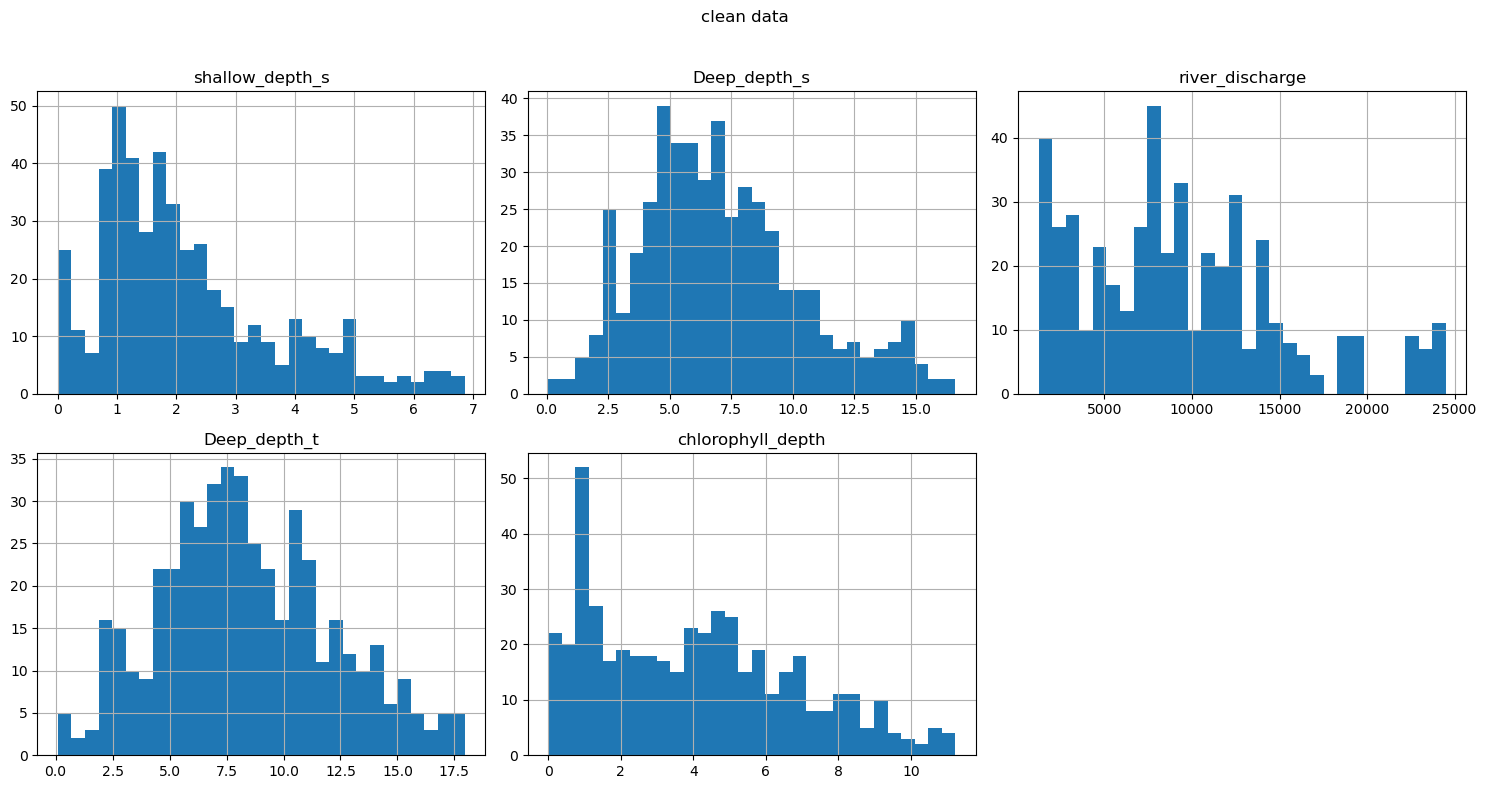

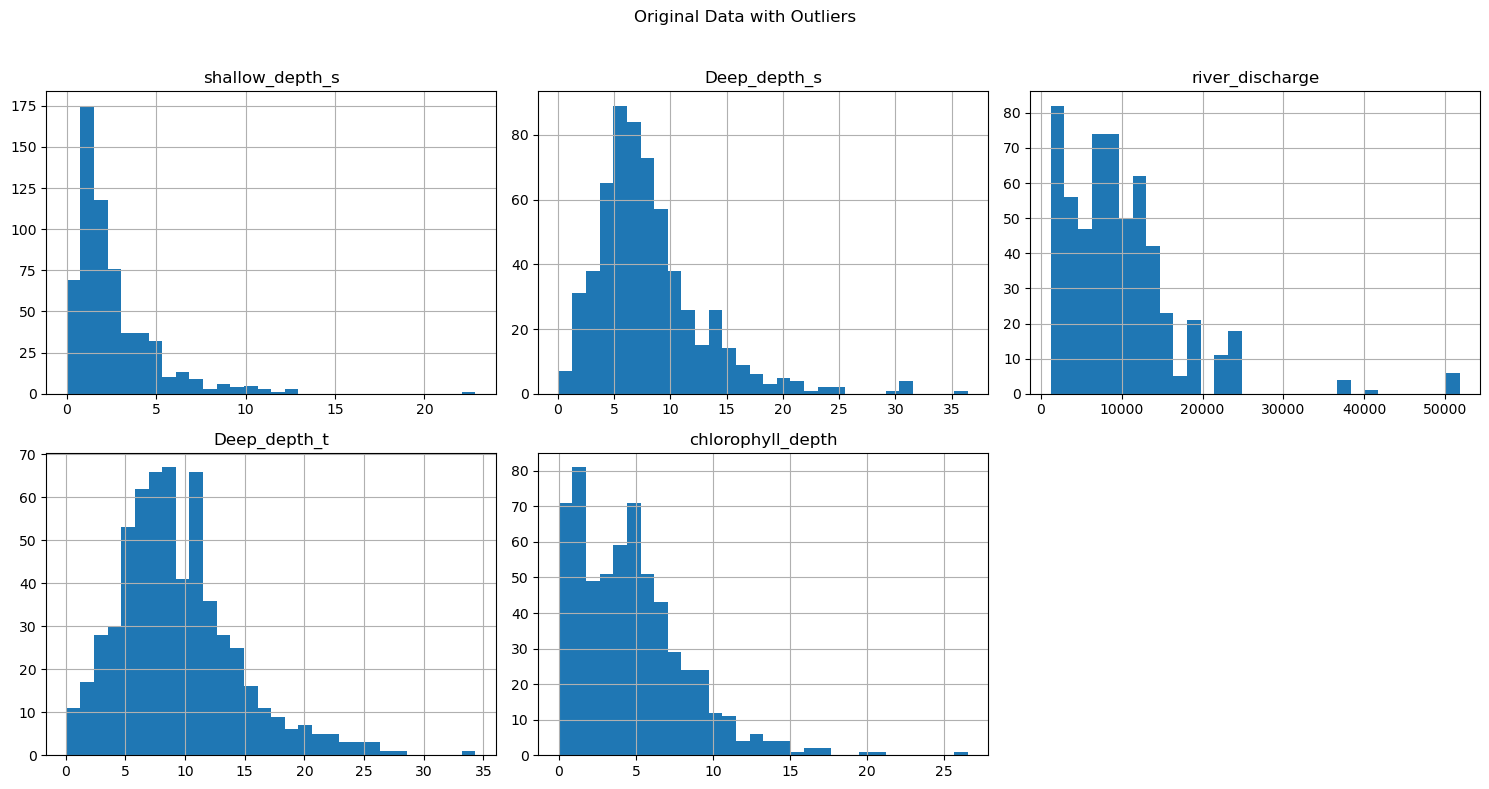

In [ ]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'Deep_depth_s','river_discharge', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 12.7954 - val_loss: 8.5258
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5949 - val_loss: 8.6746
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.8452 - val_loss: 8.6021
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3843 - val_loss: 8.6751
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.9403 - val_loss: 8.3186
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7397 - val_loss: 8.9840
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6409 - val_loss: 8.4808
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7485 - val_loss: 8.4252
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.2220 - val_loss: 8.5949
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0904 - val_loss: 8.7062
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.5767 - val_loss: 8.3691
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6046 - val_

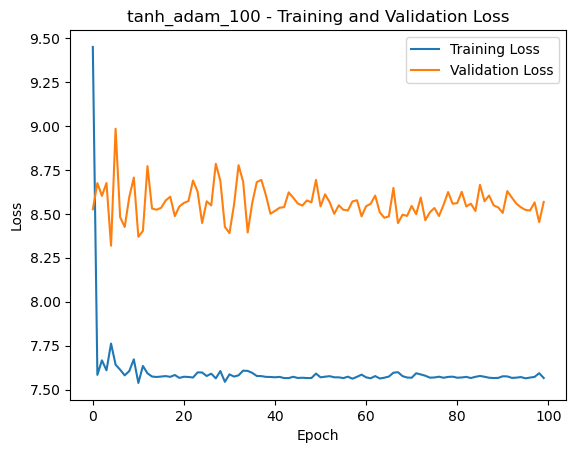

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 11.5342 - val_loss: 8.9839
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.1932 - val_loss: 8.2998
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7615 - val_loss: 8.6168
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1140 - val_loss: 8.9701
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3123 - val_loss: 8.4202
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7831 - val_loss: 8.4191
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.7439 - val_loss: 8.5969
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3861 - val_loss: 8.6586
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1165 - val_loss: 8.4575
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3425 - val_loss: 8.5977
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.0230 - val_loss: 8.7889
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5240 - val_

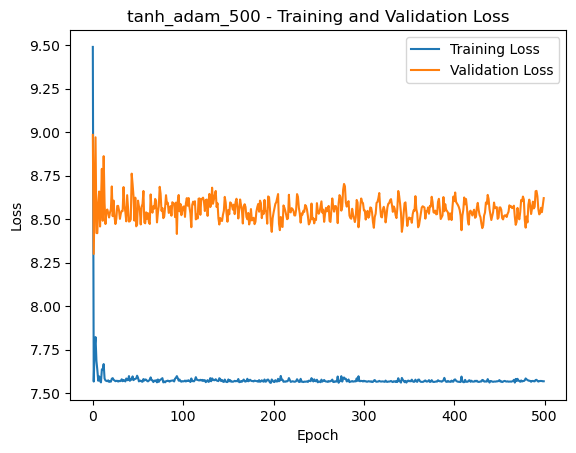

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 13.1680 - val_loss: 8.2782
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4303 - val_loss: 8.5929
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1411 - val_loss: 8.2648
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5482 - val_loss: 8.5797
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5350 - val_loss: 8.2399
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.0732 - val_loss: 8.2309
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.3615 - val_loss: 9.1828
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7005 - val_loss: 8.3058
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6420 - val_loss: 8.3679
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1700 - val_loss: 9.6933
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5330 - val_loss: 8.2889
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8003 - val_

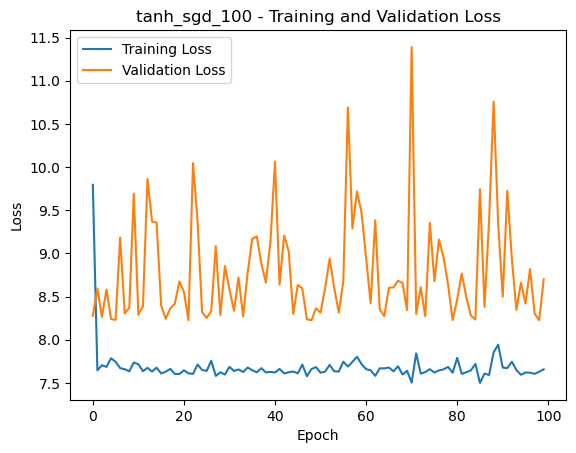

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 12.2939 - val_loss: 8.5540
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1015 - val_loss: 8.6938
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9428 - val_loss: 9.5049
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3283 - val_loss: 8.2360
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7512 - val_loss: 8.5914
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1835 - val_loss: 8.9456
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3540 - val_loss: 8.9032
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7188 - val_loss: 8.5344
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1080 - val_loss: 8.8794
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5429 - val_loss: 8.5308
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7181 - val_loss: 8.8433
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.8371 - val_

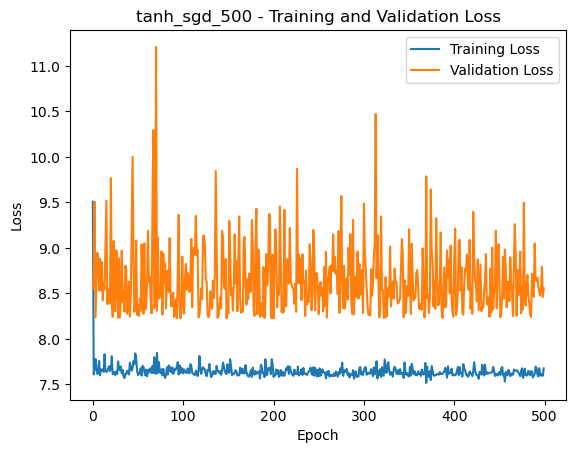

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 9.7015 - val_loss: 8.4204
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.3107 - val_loss: 8.4055
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9873 - val_loss: 8.8699
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7520 - val_loss: 8.3703
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.0240 - val_loss: 8.7671
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.9851 - val_loss: 9.0613
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.4675 - val_loss: 8.3290
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.2107 - val_loss: 8.5623
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.0322 - val_loss: 8.5646
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.1135 - val_loss: 8.7185
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.1374 - val_loss: 8.8099
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9563 - val_l

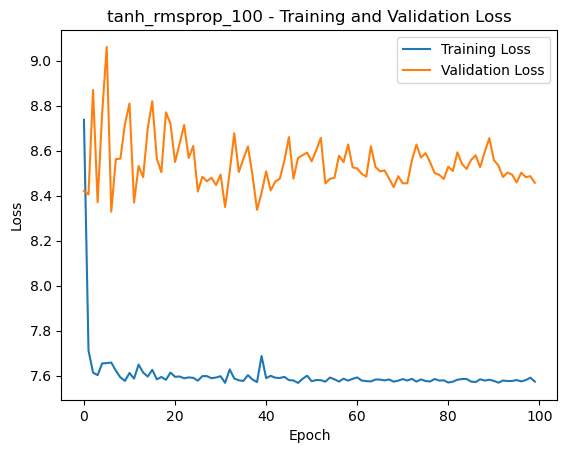

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 15.8451 - val_loss: 8.9248
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3622 - val_loss: 8.2910
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1946 - val_loss: 8.8269
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5834 - val_loss: 8.8336
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9535 - val_loss: 8.4041
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1416 - val_loss: 8.6305
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3876 - val_loss: 8.7057
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8058 - val_loss: 8.9877
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6301 - val_loss: 8.4204
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6731 - val_loss: 8.8398
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5644 - val_loss: 8.5900
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5633 - val_

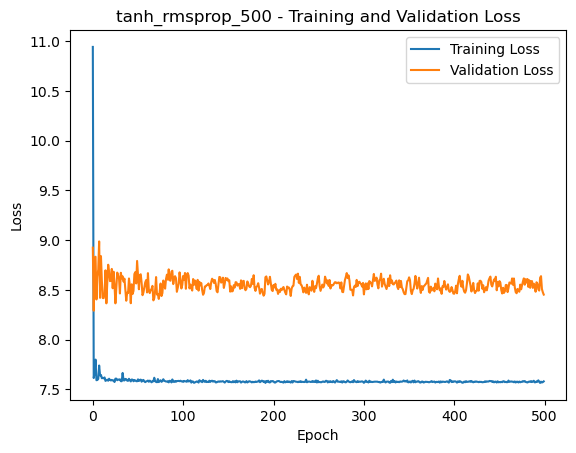

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 21.7562 - val_loss: 14.0501
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 15.9153 - val_loss: 10.8577
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 10.6989 - val_loss: 9.4486
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.0932 - val_loss: 8.7740
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.0210 - val_loss: 8.4404
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.5919 - val_loss: 8.2890
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7417 - val_loss: 8.2331
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1348 - val_loss: 8.2285
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.6014 - val_loss: 8.2555
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.6281 - val_loss: 8.2907
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.5214 - val_loss: 8.3250
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3254 - 

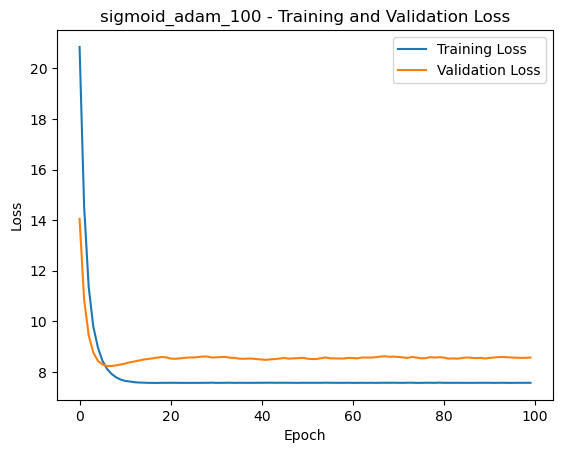

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 19.2634 - val_loss: 12.5555
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 14.0356 - val_loss: 10.2067
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 11.9107 - val_loss: 9.0624
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.8976 - val_loss: 8.5451
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.0179 - val_loss: 8.3177
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.1629 - val_loss: 8.2350
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.1206 - val_loss: 8.2298
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.8014 - val_loss: 8.2594
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.5247 - val_loss: 8.2969
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6605 - val_loss: 8.3538
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8992 - val_loss: 8.3921
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.2393 -

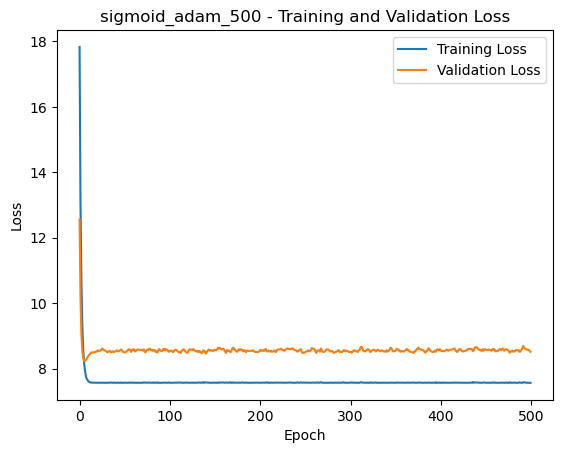

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 14.1915 - val_loss: 8.4117
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7516 - val_loss: 8.5026
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0258 - val_loss: 8.4013
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6344 - val_loss: 9.1531
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6185 - val_loss: 8.2971
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7551 - val_loss: 8.3663
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8523 - val_loss: 8.6054
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.7970 - val_loss: 8.2882
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8197 - val_loss: 8.2975
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3296 - val_loss: 8.7545
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4321 - val_loss: 8.9199
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8707 - val_

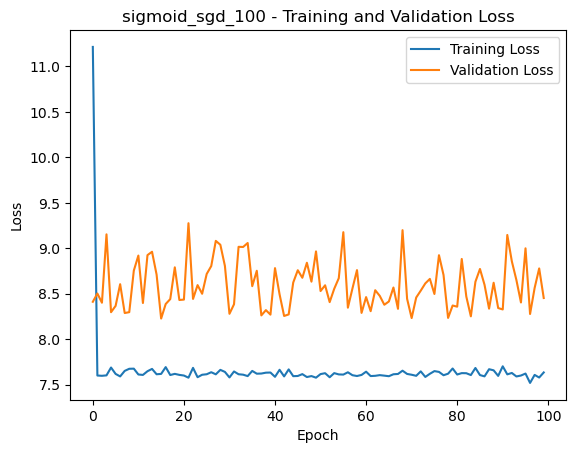

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 11.2440 - val_loss: 8.4388
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4273 - val_loss: 8.4627
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.5101 - val_loss: 8.2261
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.5579 - val_loss: 8.7329
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4212 - val_loss: 8.2291
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5861 - val_loss: 8.8417
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6787 - val_loss: 9.2611
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.4927 - val_loss: 8.2933
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.0762 - val_loss: 8.3709
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.1674 - val_loss: 8.8270
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.1860 - val_loss: 8.3121
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.9564 - val_

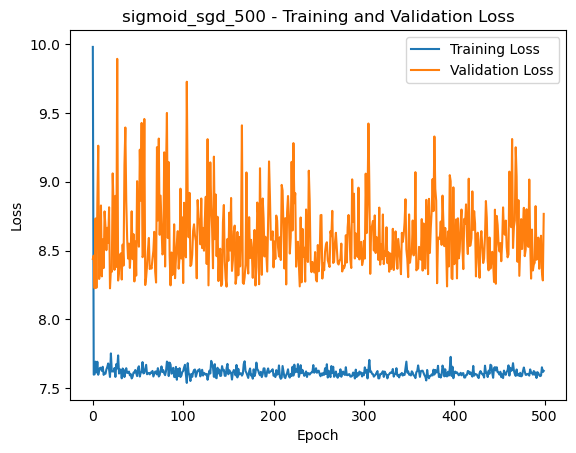

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 20.6406 - val_loss: 11.6959
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13.9137 - val_loss: 9.4500
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.5692 - val_loss: 8.5574
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8773 - val_loss: 8.2797
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8457 - val_loss: 8.2279
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.4221 - val_loss: 8.2864
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.8489 - val_loss: 8.3373
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7944 - val_loss: 8.4310
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1912 - val_loss: 8.4530
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.0150 - val_loss: 8.4223
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7.5067 - val_loss: 8.4211
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3778 - va

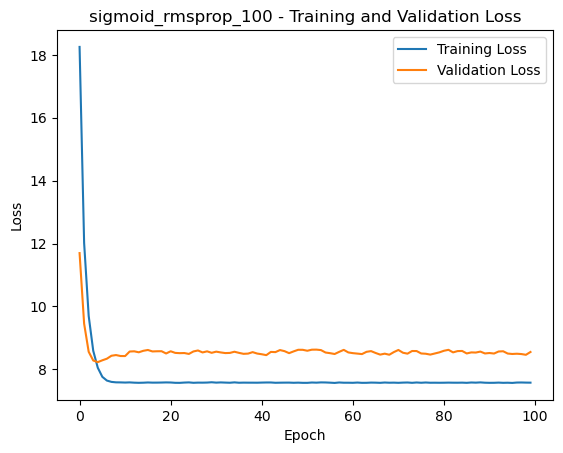

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 19.0161 - val_loss: 11.7057
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 12.1158 - val_loss: 9.4713
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.7188 - val_loss: 8.6534
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5822 - val_loss: 8.3072
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6281 - val_loss: 8.2298
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.9145 - val_loss: 8.2474
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8366 - val_loss: 8.2979
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.4038 - val_loss: 8.4043
Epoch 9/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.3685 - val_loss: 8.4938
Epoch 10/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7482 - val_loss: 8.4875
Epoch 11/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.1324 - val_loss: 8.4535
Epoch 12/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.6229 - va

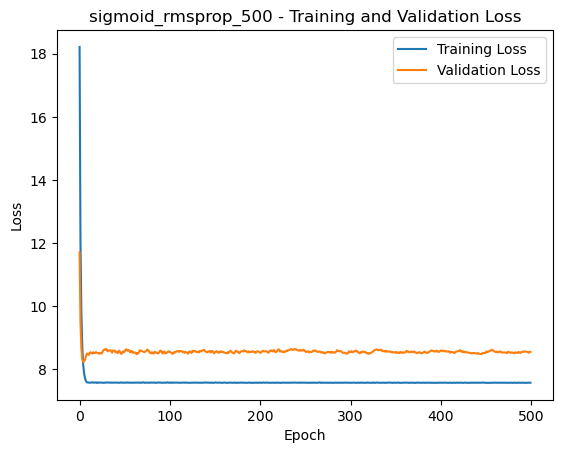

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense  # <-- Add this import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [100, 500]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [13]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
sigmoid_adam_100: Test MSE = 7.28281
tanh_adam_100: Test MSE = 7.28281
tanh_sgd_500: Test MSE = 7.2829
sigmoid_rmsprop_100: Test MSE = 7.28298
sigmoid_rmsprop_500: Test MSE = 7.28304
tanh_adam_500: Test MSE = 7.28486
sigmoid_adam_500: Test MSE = 7.28519
tanh_rmsprop_100: Test MSE = 7.29325
tanh_sgd_100: Test MSE = 7.29406
sigmoid_sgd_100: Test MSE = 7.29407
tanh_rmsprop_500: Test MSE = 7.2941
sigmoid_sgd_500: Test MSE = 7.30588


Model: tanh_adam_10, Test MSE: 6.196041107177734
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


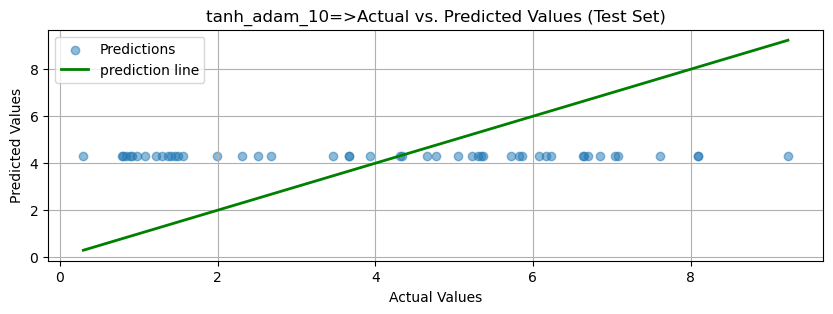

Model: tanh_adam_25, Test MSE: 6.145979404449463
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


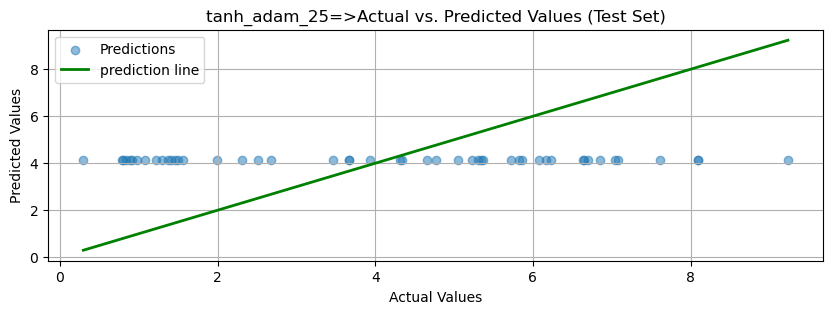

Model: tanh_adam_50, Test MSE: 6.155141353607178
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7aeb3c523880> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


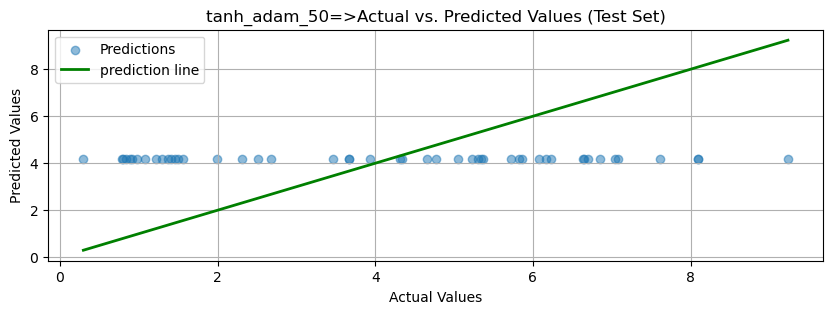

Model: tanh_adam_100, Test MSE: 6.146215438842773
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


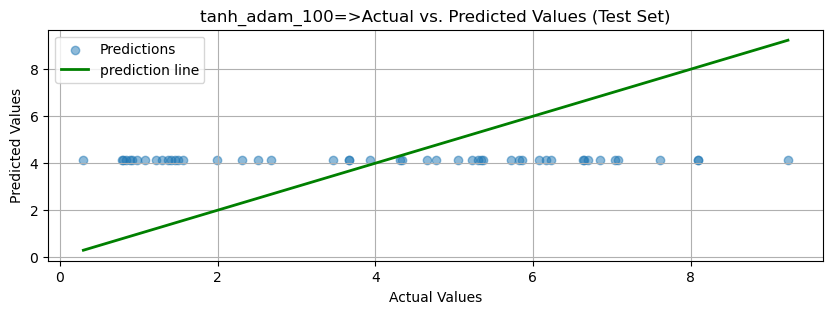

Model: tanh_adam_500, Test MSE: 6.156628131866455
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


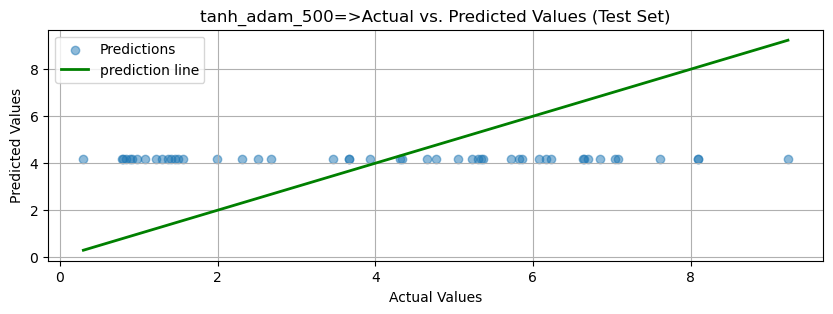

Model: tanh_adam_1000, Test MSE: 6.1735053062438965
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step 


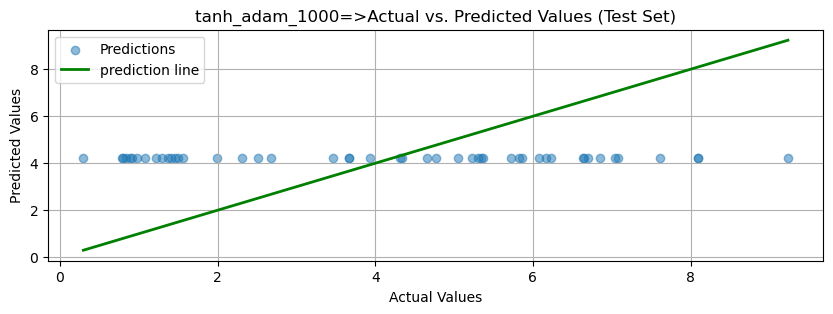

Model: tanh_sgd_10, Test MSE: 6.144450664520264
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


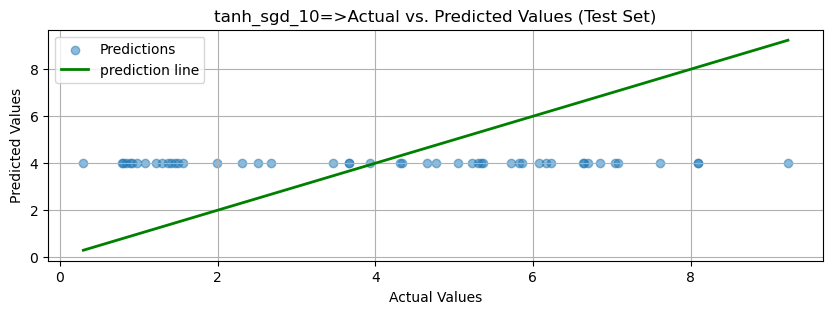

Model: tanh_sgd_25, Test MSE: 6.204868316650391
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


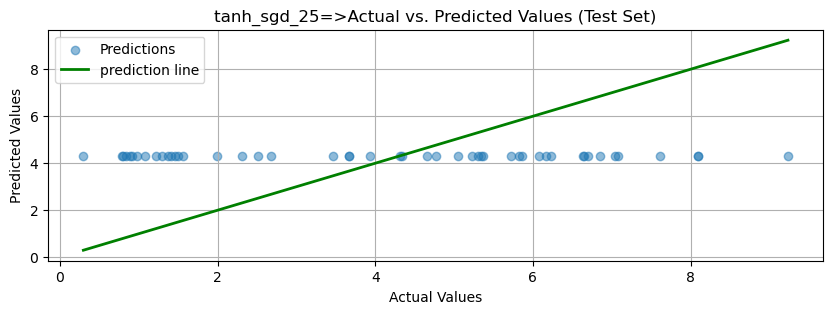

Model: tanh_sgd_50, Test MSE: 6.154842853546143
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


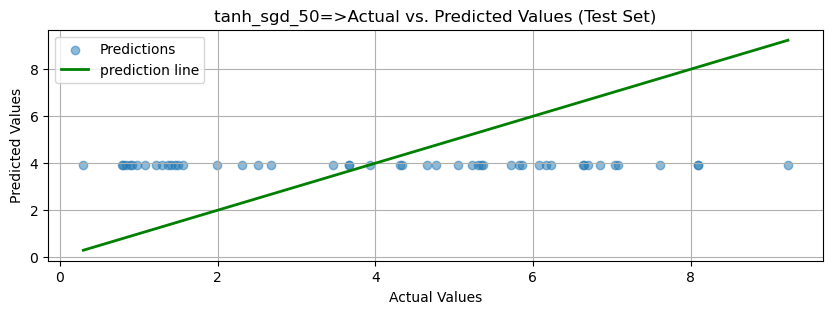

Model: tanh_sgd_100, Test MSE: 6.29152250289917
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


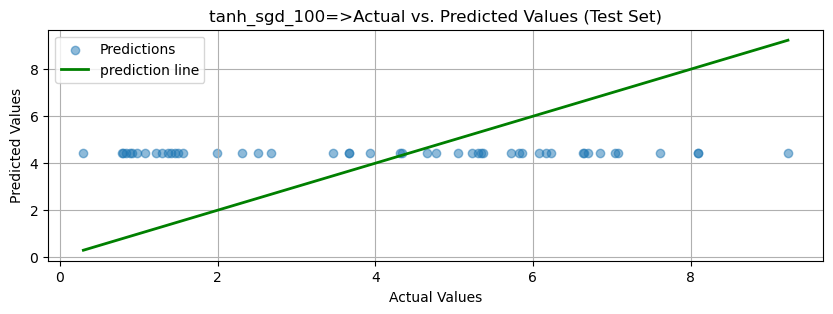

Model: tanh_sgd_500, Test MSE: 6.173741817474365
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


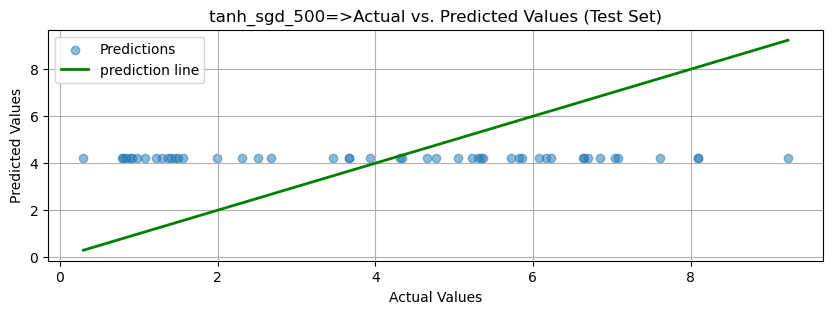

Model: tanh_sgd_1000, Test MSE: 6.183196544647217
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


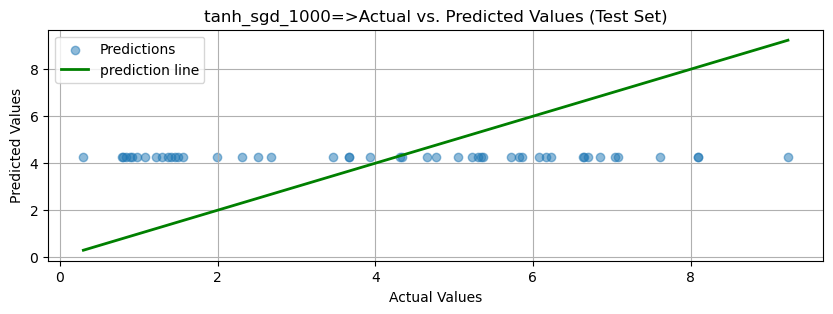

Model: tanh_rmsprop_10, Test MSE: 6.3345112800598145
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


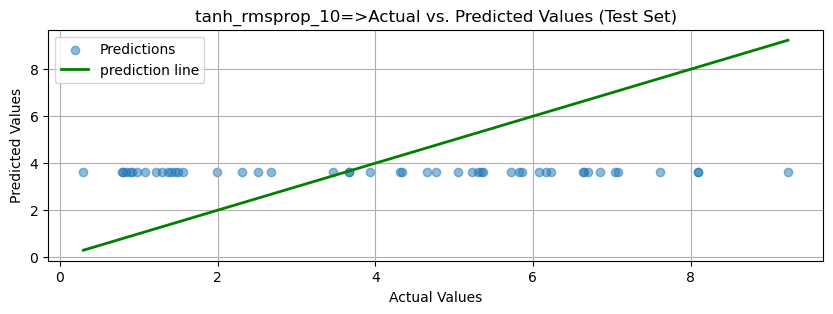

Model: tanh_rmsprop_25, Test MSE: 6.14967679977417
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


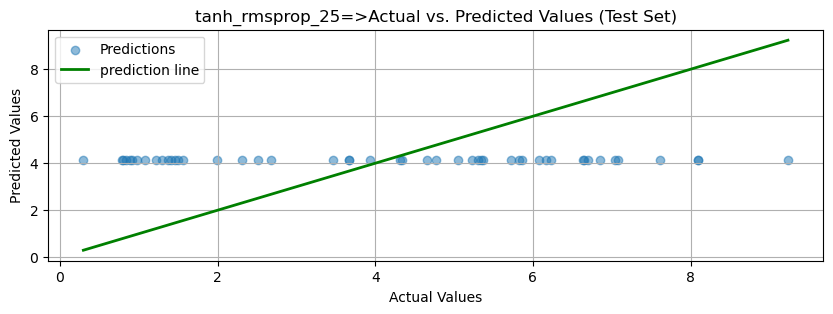

Model: tanh_rmsprop_50, Test MSE: 6.147008895874023
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


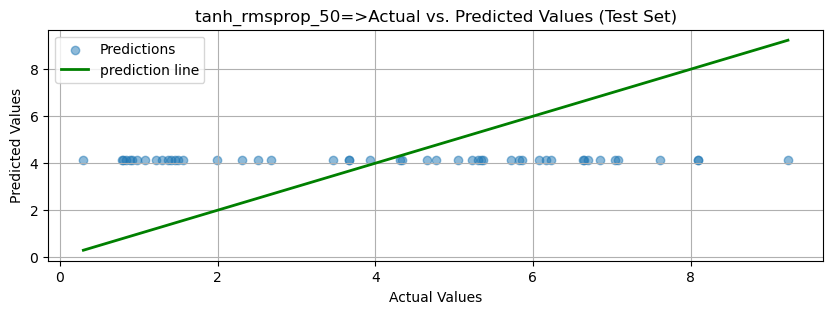

Model: tanh_rmsprop_100, Test MSE: 6.16388463973999
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


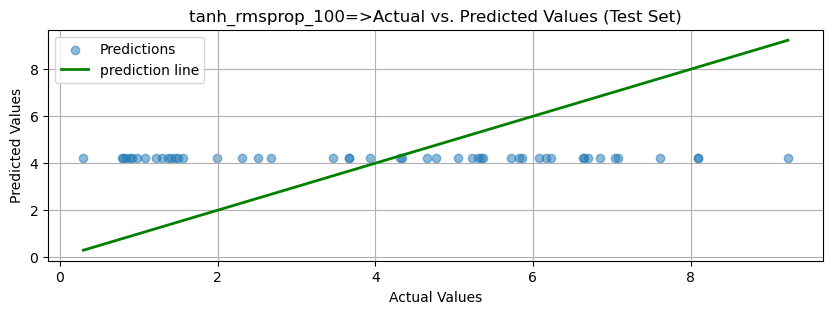

Model: tanh_rmsprop_500, Test MSE: 6.175833225250244
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


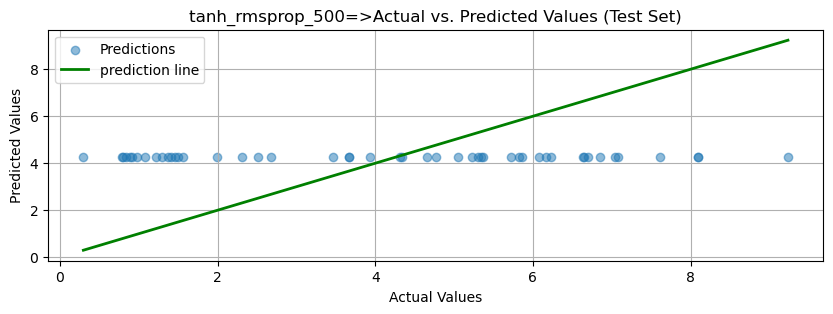

Model: tanh_rmsprop_1000, Test MSE: 6.148377895355225
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


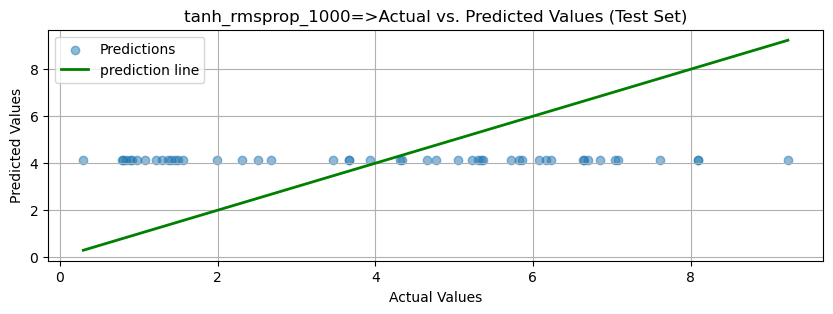

Model: sigmoid_adam_10, Test MSE: 6.155795574188232
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


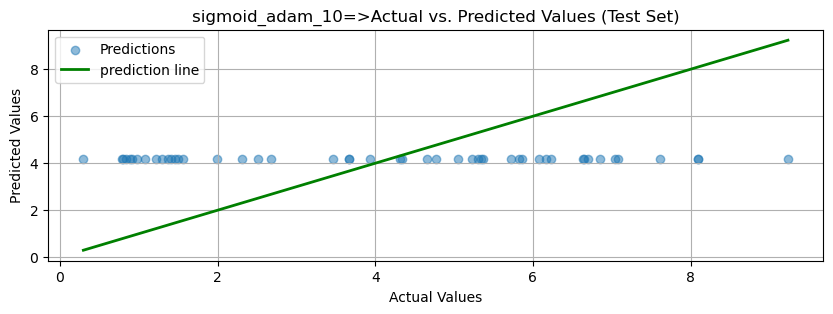

Model: sigmoid_adam_25, Test MSE: 6.144007205963135
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


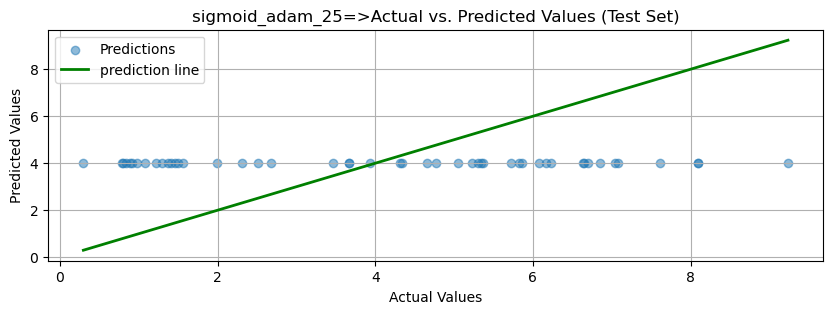

Model: sigmoid_adam_50, Test MSE: 6.144303798675537
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


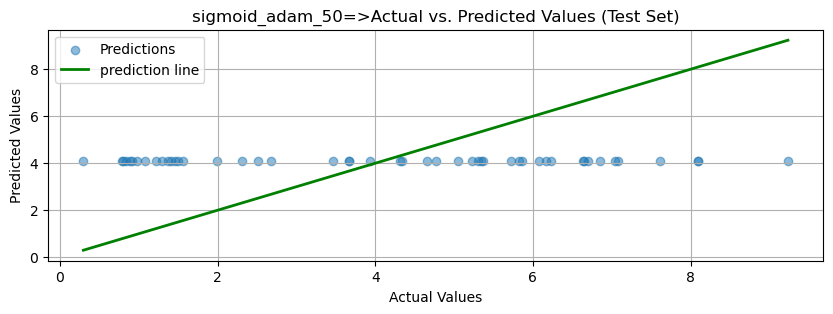

Model: sigmoid_adam_100, Test MSE: 6.146644592285156
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


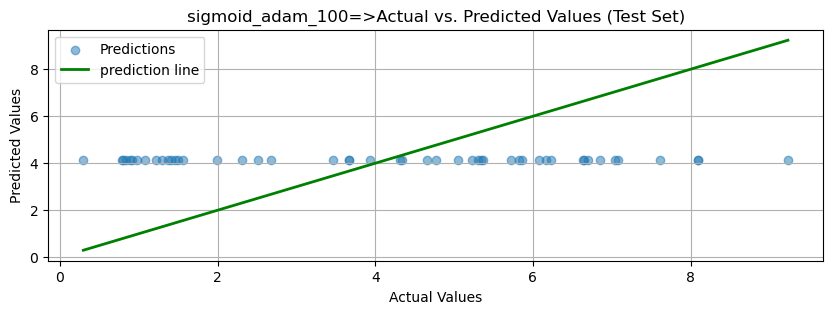

Model: sigmoid_adam_500, Test MSE: 6.153565883636475
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


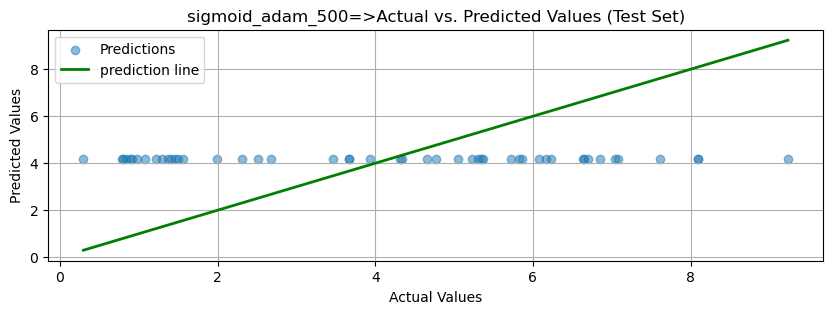

Model: sigmoid_adam_1000, Test MSE: 6.153316020965576
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


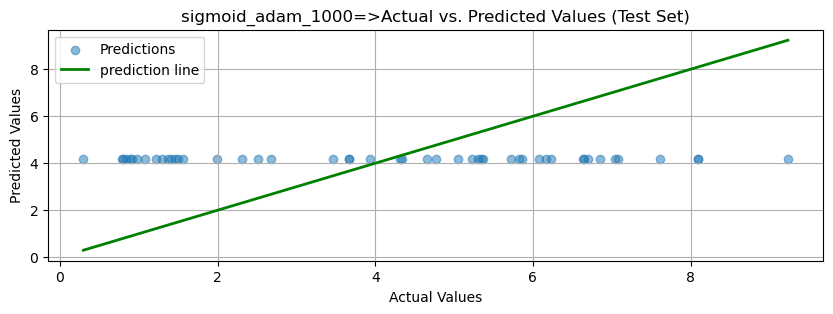

Model: sigmoid_sgd_10, Test MSE: 6.1427435874938965
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


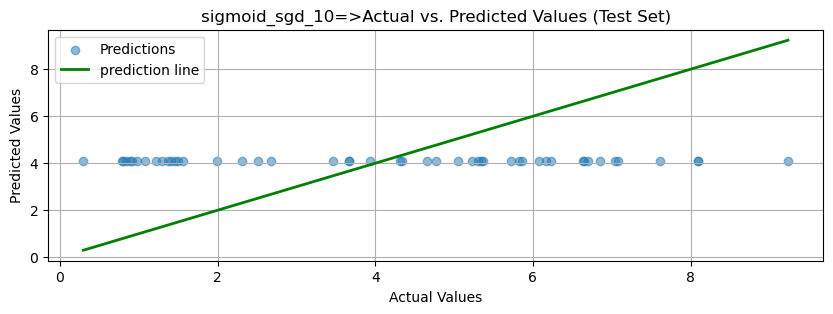

Model: sigmoid_sgd_25, Test MSE: 6.143955230712891
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


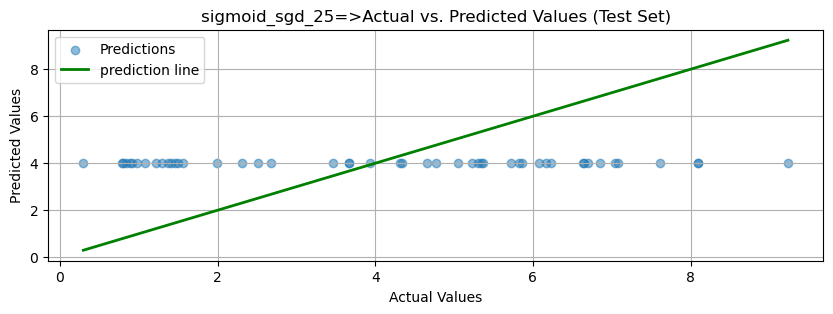

Model: sigmoid_sgd_50, Test MSE: 6.153108596801758
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


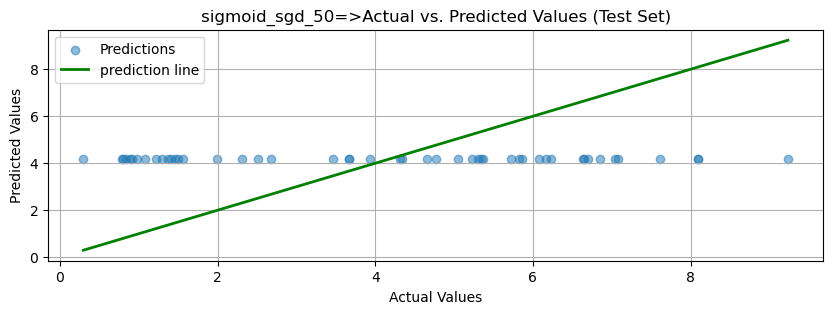

Model: sigmoid_sgd_100, Test MSE: 6.154016494750977
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


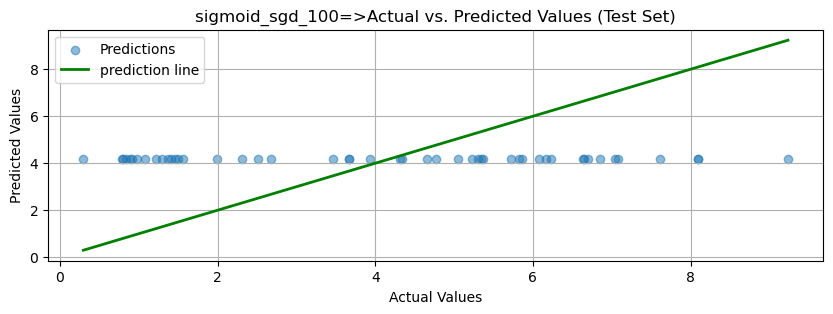

Model: sigmoid_sgd_500, Test MSE: 6.147472381591797
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


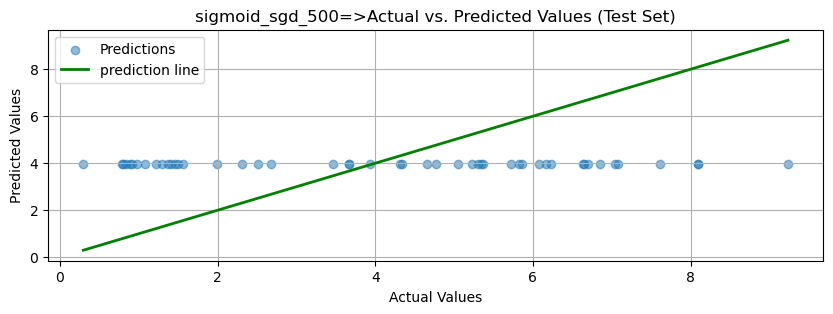

Model: sigmoid_sgd_1000, Test MSE: 6.154560089111328
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


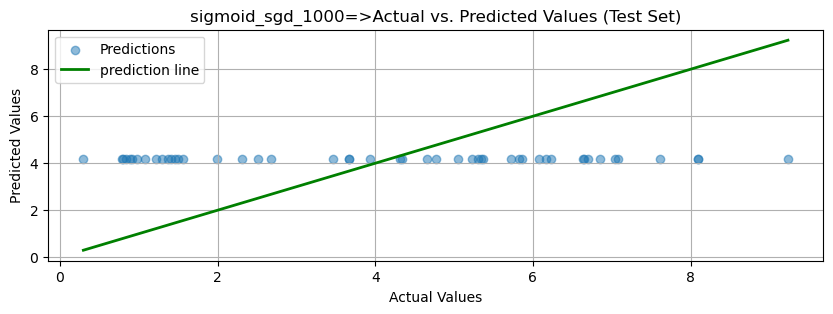

Model: sigmoid_rmsprop_10, Test MSE: 6.14941930770874
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


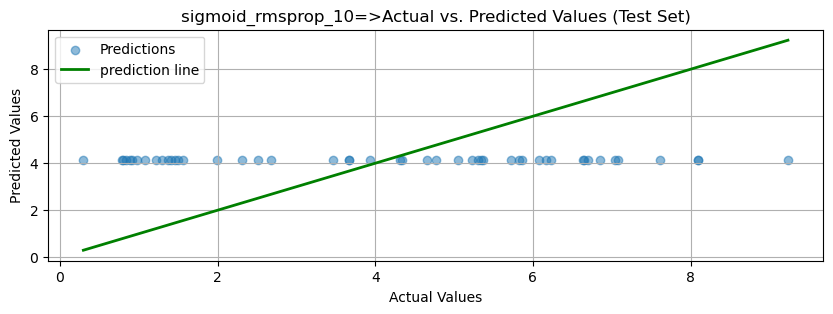

Model: sigmoid_rmsprop_25, Test MSE: 6.152977466583252
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


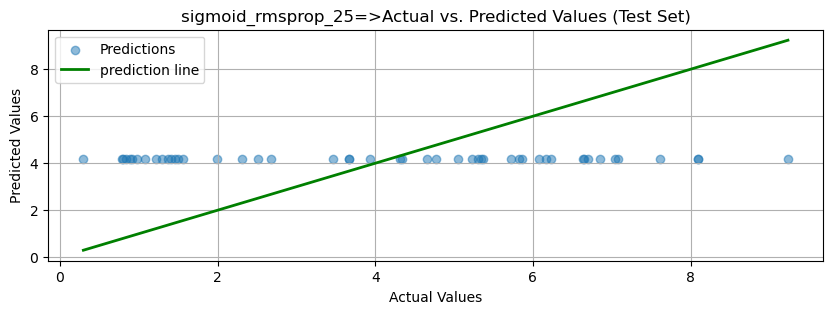

Model: sigmoid_rmsprop_50, Test MSE: 6.141725063323975
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


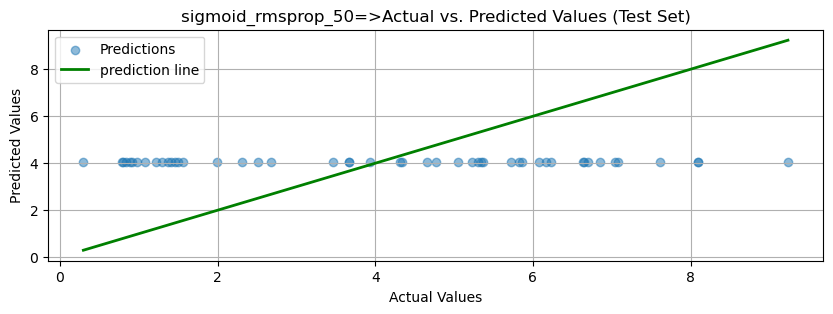

Model: sigmoid_rmsprop_100, Test MSE: 6.159847736358643
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


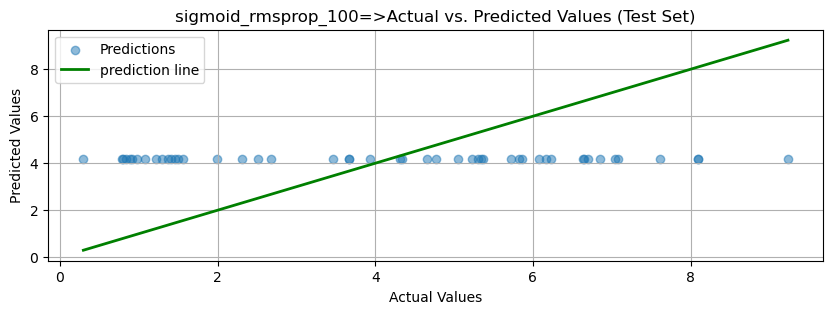

Model: sigmoid_rmsprop_500, Test MSE: 6.156137943267822
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


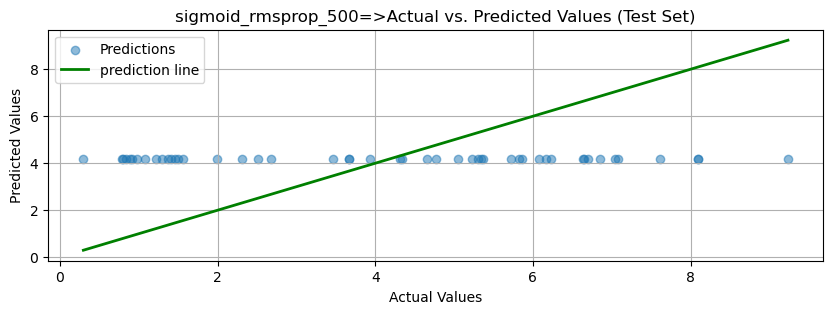

Model: sigmoid_rmsprop_1000, Test MSE: 6.15233850479126
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


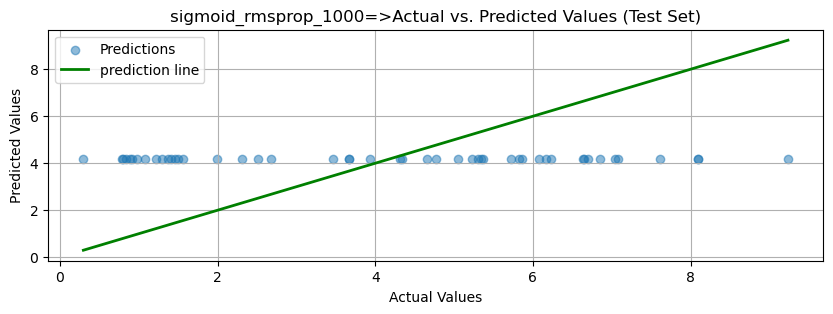

In [4]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")